## Basic Chatbot with LangGraph(Graph API)

In [1]:
import sys
import ipykernel

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)
print("IPyKernel Version:", ipykernel.__version__)
import sys

print("Python Executable:", sys.executable)
print("Python Version:", sys.version)
import sys
!{sys.executable} -m pip install langgraph langchain langchain-groq langchain-core ipykernel python-dotenv

Python Version: 3.12.15 (main, Oct  9 2026, 15:21:55) [MSC v.1944 64 bit (AMD64)]
Python Executable: e:\Beeresh's Project\AgenticAI\langgraph-1\.venv312\Scripts\python.exe
IPyKernel Version: 7.4.0
Python Executable: e:\Beeresh's Project\AgenticAI\langgraph-1\.venv312\Scripts\python.exe
Python Version: 3.12.15 (main, Oct  9 2026, 15:21:55) [MSC v.1944 64 bit (AMD64)]


'e:\Beeresh's' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "langgraph==1.2.22"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nPIP OUTPUT:\n", result.stdout)
print("\nPIP ERROR:\n", result.stderr)

Return code: 0

PIP OUTPUT:


PIP ERROR:
 


In [3]:
import sys
import ipykernel
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

print("Python:", sys.version)
print("Executable:", sys.executable)
print("IPyKernel:", ipykernel.__version__)
print("LangGraph: Successfully imported!")

Python: 3.12.15 (main, Oct  9 2026, 15:21:55) [MSC v.1944 64 bit (AMD64)]
Executable: e:\Beeresh's Project\AgenticAI\langgraph-1\.venv312\Scripts\python.exe
IPyKernel: 7.4.0
LangGraph: Successfully imported!


In [4]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

print("LangGraph imported successfully!")

from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, END, START
from langgraph.graph.message import add_messages

LangGraph imported successfully!


In [5]:
class State(TypedDict):
    messages: Annotated[list, add_messages]


    
graph_builder = StateGraph(State)

In [6]:
graph_builder

In [7]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model("openai/gpt-oss-120b", model_provider='groq')
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002AC1A24A180>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002AC1A1D70E0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [8]:
def chatbot(state:State):
    return {"messages":[model.invoke(state["messages"])]}

In [9]:
graph_builder = StateGraph(State)

graph_builder.add_node("llmchatbot", chatbot)
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

graph = graph_builder.compile()

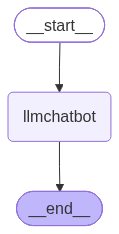

In [10]:
from IPython.display import Image, display

# Dispaly image
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [11]:
res = graph.invoke({"messages":"hi I am Beeresh...do u know whats the day of 28 july 120005"})

In [12]:
res["messages"][-1].content

'Hi\u202fBeeresh! 👋  \n\nThe date **28\u202fJuly\u202f120\u202f005** falls on a **Thursday** (using the proleptic Gregorian calendar, i.e., the modern Gregorian rules extended far into the future).\n\n**How it’s calculated**\n\nA common way to find the day‑of‑week for any Gregorian date is **Zeller’s Congruence**. Here’s a quick rundown of the steps for your date:\n\n| Symbol | Meaning | Value |\n|--------|---------|-------|\n|\u202fq\u202f| Day of month |\u202f28 |\n|\u202fm\u202f| Month (March\u202f=\u202f3 … February\u202f=\u202f14). July =\u202f7 |\u202f7 |\n|\u202fY\u202f| Year (unchanged because month\u202f>\u202f2) |\u202f120\u202f005 |\n|\u202fK\u202f| Year\u202f%\u202f100 (last two digits) |\u202f5 |\n|\u202fJ\u202f| ⌊Year\u202f/\u202f100⌋ (century) |\u202f1200 |\n\nPlug into Zeller’s formula for the Gregorian calendar:\n\n\\[\nh = \\bigl(q + \\big\\lfloor\\frac{13(m+1)}{5}\\big\\rfloor + K + \\big\\lfloor\\frac{K}{4}\\big\\rfloor + \\big\\lfloor\\frac{J}{4}\\big\\rfloor + 5J 

In [13]:
from langchain_tavily import TavilySearch
tool = TavilySearch(max_results=2)
tool.invoke("what is the recent AI top news")

{'query': 'what is the recent AI top news',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://aimagazine.com',
   'title': 'The Latest AI News, Insights and Reports | AI Magazine',
   'content': "AI Magazine takes a look at some of the biggest stories from the past week featuring CrowdStrike's AI kill switch and Meta's collaboration with Fourier…\n\n### This Week's Top Five Stories in AI\n\n### fal: Generative Media AI Infrastructure Races to US$800m ARR\n\n### AI-Powered Battery Discovery: What is Holyvolt?\n\n### NVIDIA, Volvo & Mercedes: Using AI for Automated Driving\n\n### Why Workday Acquired Agentic Identity Platform C1.AI\n\n## AI Applications\n\nView all [...] ### Cohere Embed 5: What Are Frontier Embedding Models?\n\n### Huawei AI Model Set to Reshape Chinese Steel Manufacturing\n\n### Could AI Imaging Spot Pregnancy Health Risks Earlier?\n\n### What Anthropic’s Research Shows About the Risks of AI\n\n### How Microsoft Azure Accelerat